In [ ]:
# import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
import seaborn as sns

# Introduction: Data Analysis, Visualization, and Modeling
To get your feet wet, we will start with the `80-cerals` dataset to start learning the basics of `pandas`, how to handle missin g values, and basic data visualization. The dataset contains $16$ columns: `name`, `mfr`, `type`, `calories`, `protein`, `fat`, `sodium`, `fiber`, `carbo`, `sugars`, `potass`, `vitamins`, `shelf`, `weight`, `cups`, and `rating`. More information from the Kaggle page is below:

```
Fields in the dataset:

Name: Name of cereal
mfr: Manufacturer of cereal
  A = American Home Food Products;
  G = General Mills
  K = Kelloggs
  N = Nabisco
  P = Post
  Q = Quaker Oats
  R = Ralston Purina

type:
  cold
  hot

calories: calories per serving

protein: grams of protein

fat: grams of fat

sodium: milligrams of sodium

fiber: grams of dietary fiber

carbo: grams of complex carbohydrates

sugars: grams of sugars

potass: milligrams of potassium

vitamins: vitamins and minerals - 0, 25, or 100, indicating the typical percentage of FDA recommended

shelf: display shelf (1, 2, or 3, counting from the floor)

weight: weight in ounces of one serving

cups: number of cups in one serving

rating: a rating of the cereals (Possibly from Consumer Reports?)
```

To get started let's first load in the dataset.

In [34]:
# download ceral dataset sales dataset from Kaggle
import kagglehub
path = kagglehub.dataset_download("crawford/80-cereals")
df = pd.read_csv(path + "/cereal.csv")

# Replace -1 with NaN in the specific columns
columns_to_clean = ['carbo', 'sugars', 'potass']

df[columns_to_clean] = df[columns_to_clean].replace(-1, np.nan)

df.head()

Using Colab cache for faster access to the '80-cereals' dataset.


,name,mfr,type,calories,protein,fat,sodium,fiber,carbo,sugars,potass,vitamins,shelf,weight,cups,rating
0,100% Bran,N,C,70,4,1,130,10.0,5.0,6.0,280.0,25,3,1.0,0.33,68.402973
1,100% Natural Bran,Q,C,120,3,5,15,2.0,8.0,8.0,135.0,0,3,1.0,1.00,33.983679
2,All-Bran,K,C,70,4,1,260,9.0,7.0,5.0,320.0,25,3,1.0,0.33,59.425505
3,All-Bran with Extra Fiber,K,C,50,4,0,140,14.0,8.0,0.0,330.0,25,3,1.0,0.50,93.704912
4,Almond Delight,R,C,110,2,2,200,1.0,14.0,8.0,NaN,25,3,1.0,0.75,34.384843


To get a better sense of the actual size of our data, let's print out its shape using the built-in Pandas `.shape` method.

In [35]:
df.shape # returns (# of rows, # of columns)

(77, 16)

Great! So we can see that our dataset has $77$ rows and $16$ columns.

Now before we continue it's important for us to make a note that often times in real-world data there will be "missing values" which can occur for a variety of reasons (e.g. someone didn't fill out a certain section in a survey, a sensor failed, etc.) which can pose a problem when we want to use the data to build a model. Often times a missing value may be denoted with `NaN` (Not a Number) or some other value to denote that a value could not be recorded. Let's look to see how many values are missing from our dataset:

In [36]:
df[df.isna().any(axis=1)].shape[0]

3

So it turns out that $3$ out of our $77$ rows have a missing value somewhere. So what do we do about these pesky missing values? One option that might come to mind is to simply "throw out" the rows in our dataset that contain a `NaN` value and use the rest, so in our case we would throw out the $3$ rows and be left with a dataset with $74$ rows instead.

In [37]:
len(df.dropna())

74

In this particular case that might not be too concerning, after all what's $3$ data points, but what happens if more of your dataset has missing values? You would end up an extremely small dataset and might have no chance of building a sensible model! So another approach is known as *data imputation* where we try to fill in missing values with a sensible replacement value (e.g. mean, median, mode, etc.), for our case let's replace the missing values with the *mean* of their respective columns.

In [38]:
# Fill NaN values in numeric columns with their respective column mean
numeric_cols = df.select_dtypes(include=['number']).columns
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].mean())

# Verify that there are no more missing values left
remaining_na = df.isna().sum().sum()
print(f"Remaining missing values in df: {remaining_na}")
display(df.head())
print(df.shape)

Remaining missing values in df: 0


,name,mfr,type,calories,protein,fat,sodium,fiber,carbo,sugars,potass,vitamins,shelf,weight,cups,rating
0,100% Bran,N,C,70,4,1,130,10.0,5.0,6.0,280.000000,25,3,1.0,0.33,68.402973
1,100% Natural Bran,Q,C,120,3,5,15,2.0,8.0,8.0,135.000000,0,3,1.0,1.00,33.983679
2,All-Bran,K,C,70,4,1,260,9.0,7.0,5.0,320.000000,25,3,1.0,0.33,59.425505
3,All-Bran with Extra Fiber,K,C,50,4,0,140,14.0,8.0,0.0,330.000000,25,3,1.0,0.50,93.704912
4,Almond Delight,R,C,110,2,2,200,1.0,14.0,8.0,98.666667,25,3,1.0,0.75,34.384843


(77, 16)


Now we have preserved all $77$ rows of our dataset! Next let's take a look at actually visualizing our dataset by plotting histograms of our numerical columns of our dataset.

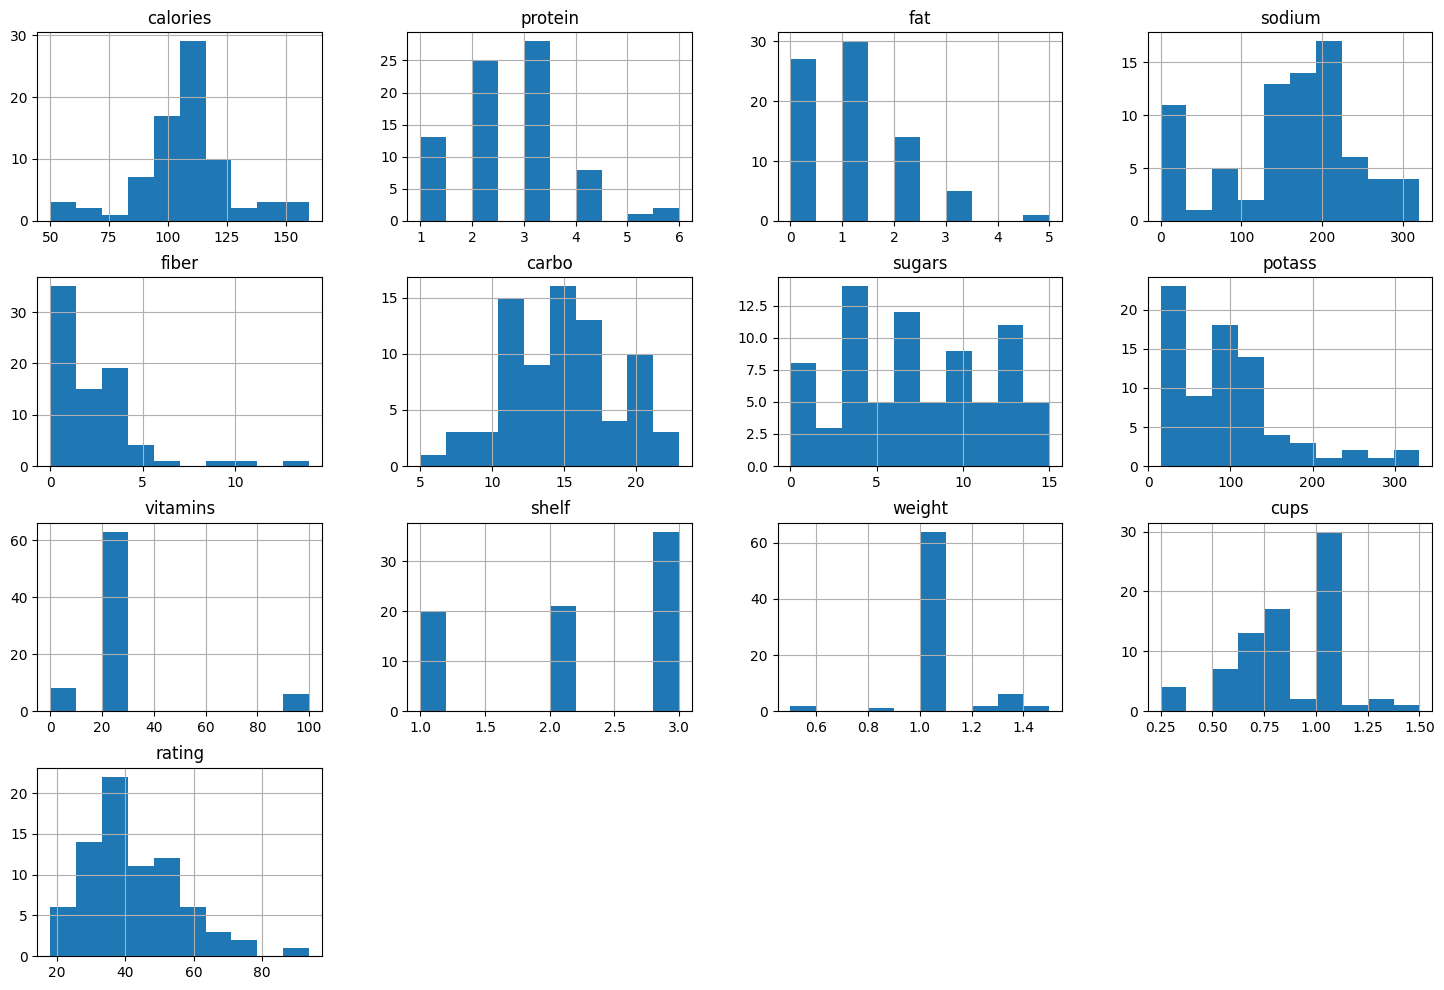

In [43]:
df.hist(figsize=(18, 12))
plt.show()

We trying to determine relationships within "features" of our data we can start by looking at a correlation matrix, so let's do that below:

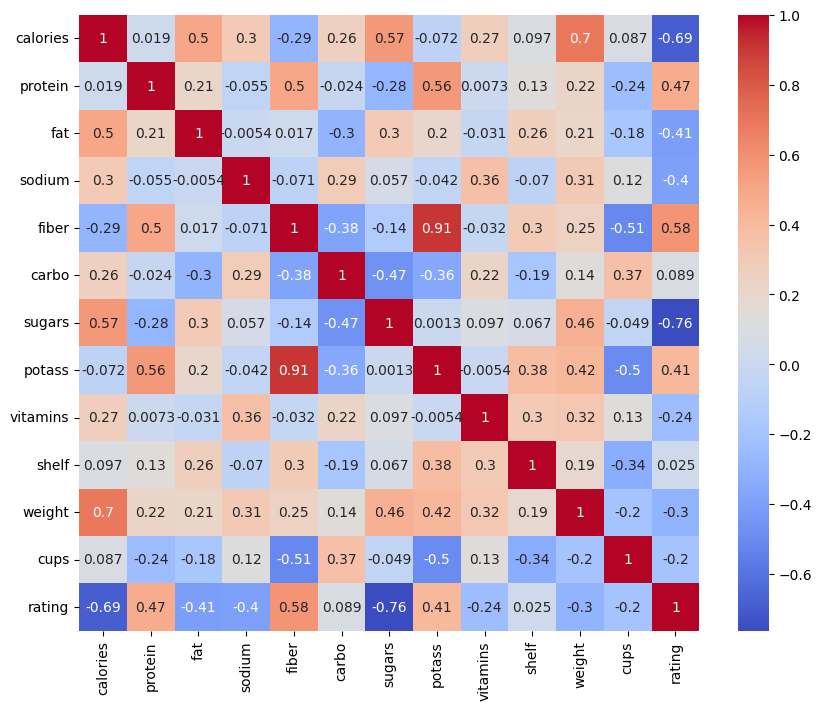

In [63]:
corr = df[numeric_cols].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.show()

It seems for example that `sugar` and `rating` are highly correlated, so let's look at `sugars vs rating`:

<Axes: xlabel='sugars', ylabel='rating'>

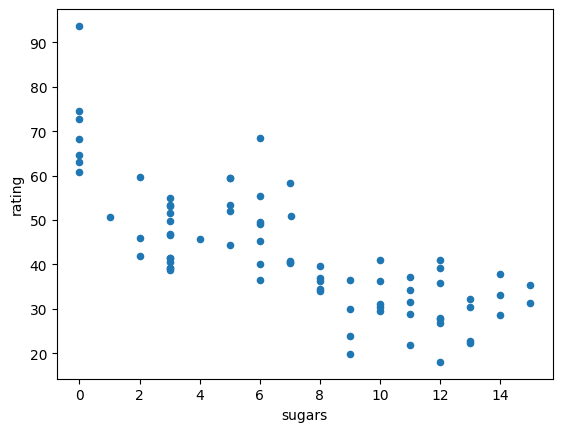

In [51]:
df.plot(kind="scatter", x="sugars", y="rating")

Now suppose, we wanted to fit a line to the sugar vs ratings relationship above. One such way is to use **Linear Regression** which aims to find the coefficients of line that minimizes the distance to all of our data points. More formally, Linear Regression is to find $\beta_0, \beta$ such that
$$
  (\beta, \beta_0) = \arg \min \frac{1}{N}\sum_{i=1}^N (\beta_0 + \beta x_i - y_i)^2
$$
the distance metric above is known as the **Mean Square Error (MSE)**. Let's use `scikit-learn` library to create a linear model using Linear Regression.


In [53]:
X = df["sugars"]
y = df["rating"]
model = LinearRegression()
model.fit(X, y)

LinearRegression()

In [57]:
print(f"Model intercept: {model.intercept_}")
print(f"Model coefficient: {model.coef_}")

Model intercept: 59.96042068710487
Model coefficient: [-2.46142021]


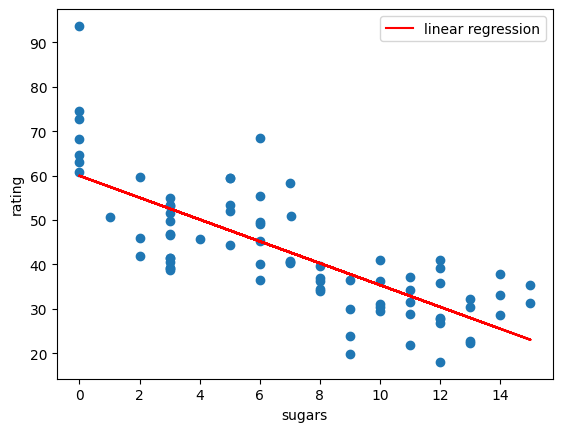

In [56]:
plt.scatter(X, y)
plt.plot(X, model.predict(X), color="red", label="linear regression")
plt.legend()
plt.xlabel("sugars")
plt.ylabel("rating")
plt.show()

In [58]:
# Compute 1D linear regression model MSE
err = mean_squared_error(y, model.predict(X))
print(f"Mean squared error: {err}")

Mean squared error: 81.62165752457801


Another metric useful for Linear Regression models is the $R^2$-score, which tells us how well our model explains the variance of $y$ with respect to $x$, and can be computed as

$$
  R^2 = 1 - \frac{\sum_{i=1}^N (y_i - \hat{y}_i)^2}{\sum_{i=1}^N (y_i - \bar{y})^2}
$$

In [71]:
# Compute 1D Linear Regression R^2 Score
r_score = model.score(X, y)
print(f"R-squared score: {r_score}")

R-squared score: 0.5809194320222828


Of course we can also use linear regression in higher-dimensions as well, so let's say we wanted to also include `fat` alongside `sugar` for predicting our `rating`

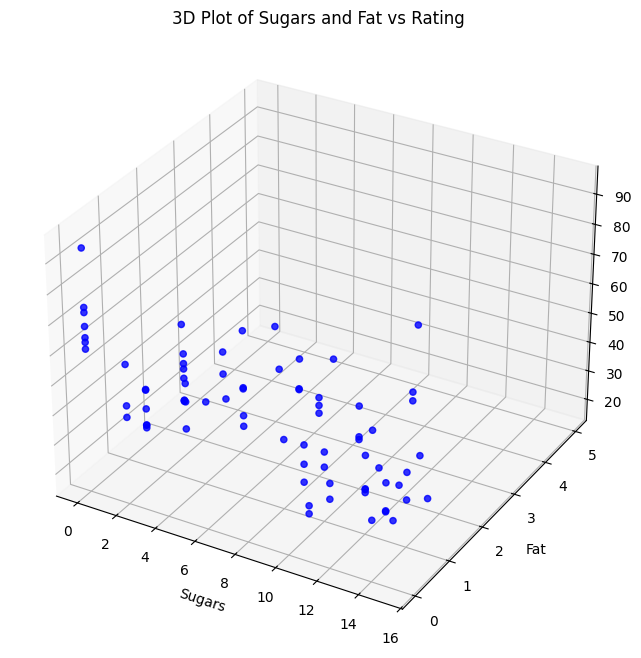

In [65]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Scatter plot
ax.scatter(df['sugars'], df['fat'], df['rating'], c='blue', marker='o', alpha=0.8)

# Set labels
ax.set_xlabel('Sugars')
ax.set_ylabel('Fat')
ax.set_zlabel('Rating')
ax.set_title('3D Plot of Sugars and Fat vs Rating')

plt.show()

In [67]:
# Define multiple features
X_multi = df[['sugars', 'fat']]
y_multi = df['rating']

# Fit the linear regression model
multi_model = LinearRegression()
multi_model.fit(X_multi, y_multi)

# Output model parameters and MSE
print(f"Model intercept: {multi_model.intercept_}")
print(f"Model coefficients (sugars, fat): {multi_model.coef_}")

multi_err = mean_squared_error(y_multi, multi_model.predict(X_multi))
print(f"Mean squared error with sugars and fat: {multi_err}")

Model intercept: 61.41021340309014
Model coefficients (sugars, fat): [-2.26913757 -2.76492318]
Mean squared error with sugars and fat: 74.66859701511163


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


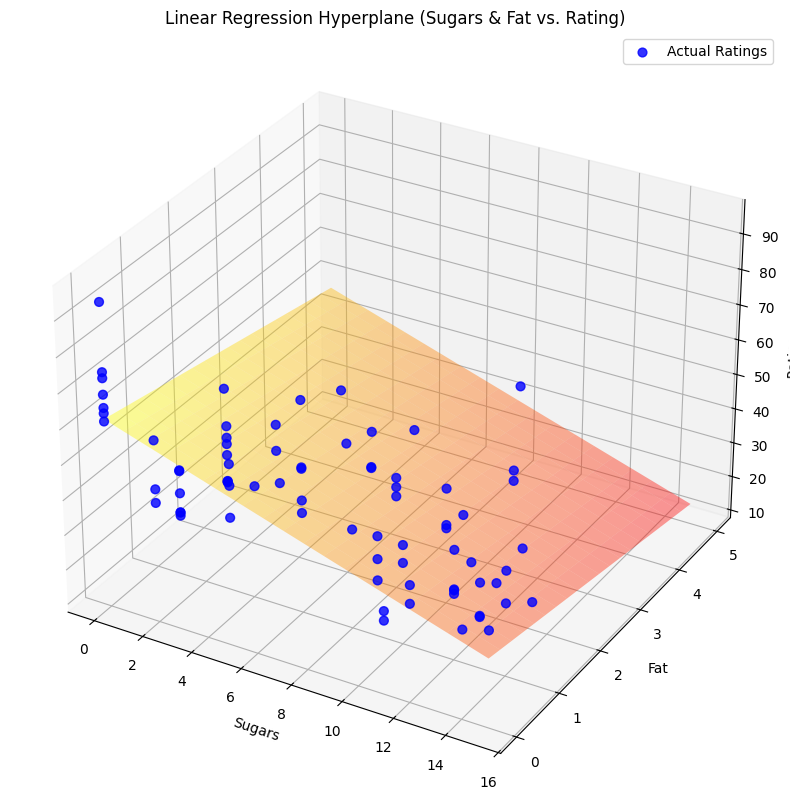

In [73]:
# Create a coordinate grid over sugars and fat
x_range = np.linspace(df['sugars'].min(), df['sugars'].max(), 20)
y_range = np.linspace(df['fat'].min(), df['fat'].max(), 20)
X_grid, Y_grid = np.meshgrid(x_range, y_range)

# Flatten the grid to run predictions, then reshape back to a 2D grid
grid_features = np.c_[X_grid.ravel(), Y_grid.ravel()]
Z_grid = multi_model.predict(grid_features).reshape(X_grid.shape)

# Initialize the 3D plot
fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')

# Plot the actual data points as a scatter plot
ax.scatter(df['sugars'], df['fat'], df['rating'], c='blue', marker='o', s=40, label='Actual Ratings', alpha=0.8)

# Plot the regression hyperplane
surface = ax.plot_surface(X_grid, Y_grid, Z_grid, cmap='autumn', alpha=0.4, rstride=1, cstride=1, edgecolor='none')

# Set labels and title
ax.set_xlabel('Sugars')
ax.set_ylabel('Fat')
ax.set_zlabel('Rating')
ax.set_title('Linear Regression Hyperplane (Sugars & Fat vs. Rating)')
ax.legend()

plt.show()

In [69]:
# Compute 2D Linear Regression Model MSE
err = mean_squared_error(y_multi, multi_model.predict(X_multi))
print(f"Mean squared error: {err}")

Mean squared error: 74.66859701511163


In [70]:
# Compute 2D Linear Regression Model R^2 Score
r_score = multi_model.score(X_multi, y_multi)
print(f"R-squared score: {r_score}")

R-squared score: 0.6166194243510733


Which seems to be an improvement on our $1$D case. Note that we are also not limited to linear models, another approach is Polynomial Regression where we want to learn the coefficients of a polynomial that minimizes the MSE.

In [110]:
X = df[["sugars"]]
y = df["rating"]

In [114]:
degree = 5
model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
model.fit(X, y)

Pipeline(steps=[('polynomialfeatures', PolynomialFeatures(degree=5)),
                ('linearregression', LinearRegression())])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


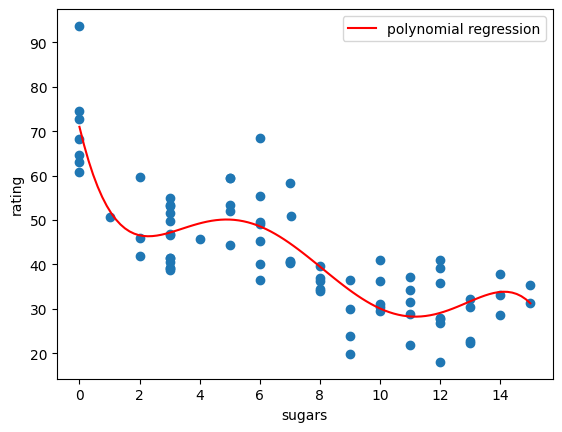

In [115]:
plt.scatter(X, y)
X_range = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
plt.plot(X_range, model.predict(X_range), color="red", label="polynomial regression")
plt.legend()
plt.xlabel("sugars")
plt.ylabel("rating")
plt.show()

In [104]:
# Compute Polynomial Regression Model MSE
err = mean_squared_error(y, model.predict(X))
print(f"Mean squared error: {err}")

Mean squared error: 73.5803985582964


In [105]:
# Compute Polymial Regression Model R^2-Score
print(f"R-squared score: {model.score(X, y)}")

R-squared score: 0.6222067015662816


In [108]:
X_train, y_train, X_test, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [116]:
# Correct the train/test split unpacking order
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

for degree in range(1, 10):
    model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    print(f"Degree {degree} -> MSE: {mse:.4f}, R2: {r2:.4f}")

Degree 1 -> MSE: 97.5263, R2: 0.4031
Degree 2 -> MSE: 91.5264, R2: 0.4398
Degree 3 -> MSE: 99.4780, R2: 0.3912
Degree 4 -> MSE: 105.6413, R2: 0.3535
Degree 5 -> MSE: 80.6791, R2: 0.5062
Degree 6 -> MSE: 79.4192, R2: 0.5139
Degree 7 -> MSE: 219.9258, R2: -0.3460
Degree 8 -> MSE: 317.9413, R2: -0.9459
Degree 9 -> MSE: 86.4872, R2: 0.4707


In [117]:
# cross-val
for degree in range(1, 10):
    model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
    scores = cross_val_score(model, X, y, cv=5, scoring='neg_mean_squared_error')
    print(f"Degree {degree} -> MSE: {scores.mean():.4f}")

Degree 1 -> MSE: -85.4607
Degree 2 -> MSE: -78.2158
Degree 3 -> MSE: -80.2955
Degree 4 -> MSE: -69.7452
Degree 5 -> MSE: -61.4345
Degree 6 -> MSE: -62.1903
Degree 7 -> MSE: -61.6052
Degree 8 -> MSE: -61.5854
Degree 9 -> MSE: -61.1900


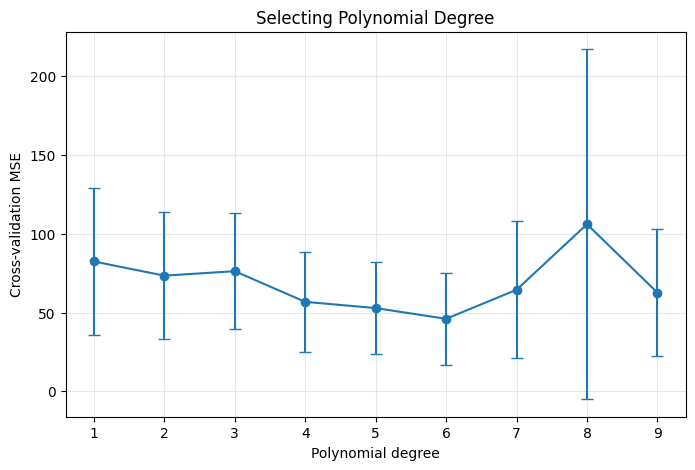

Best degree by CV: 6
Final test MSE: 105.81


In [118]:

from sklearn.model_selection import KFold, cross_val_score

# Remove missing observations, if any
data = df[["sugars", "rating"]].dropna()
X = data[["sugars"]]
y = data["rating"]

# Reserve 20% for final testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

degrees = range(1, 10)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

mean_mse = []
std_mse = []

for degree in degrees:
    model = make_pipeline(
        PolynomialFeatures(degree, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )

    scores = -cross_val_score(
        model, X_train, y_train,
        cv=cv, scoring="neg_mean_squared_error"
    )

    mean_mse.append(scores.mean())
    std_mse.append(scores.std())

# Plot mean validation error
plt.figure(figsize=(8, 5))
plt.errorbar(
    list(degrees), mean_mse,
    yerr=std_mse, marker="o", capsize=4
)
plt.xlabel("Polynomial degree")
plt.ylabel("Cross-validation MSE")
plt.title("Selecting Polynomial Degree")
plt.xticks(list(degrees))
plt.grid(alpha=0.3)
plt.show()

# Select the degree with minimum CV error
best_degree = list(degrees)[np.argmin(mean_mse)]
print(f"Best degree by CV: {best_degree}")

# Fit on all training data
best_model = make_pipeline(
    PolynomialFeatures(best_degree, include_bias=False),
    StandardScaler(),
    LinearRegression()
)
best_model.fit(X_train, y_train)

# Evaluate on untouched test data
test_mse = mean_squared_error(
    y_test, best_model.predict(X_test)
)
print(f"Final test MSE: {test_mse:.2f}")
